In [56]:
import numpy as np
X = np.array([[2,3],[2,5],[5,3],[6,7],[8,6]])
labels = ["P1", "P2", "P3", "P4", "P5"]

In [57]:
from scipy.spatial.distance import pdist, squareform
D = squareform(pdist(X, metric="euclidean"))
print(np.round(D,2))

[[0.   2.   3.   5.66 6.71]
 [2.   0.   3.61 4.47 6.08]
 [3.   3.61 0.   4.12 4.24]
 [5.66 4.47 4.12 0.   2.24]
 [6.71 6.08 4.24 2.24 0.  ]]


In [58]:
def diameter(cluster):
    if len(cluster) < 2:
        return 0.0
    return max(D[i, j] for i in cluster for j in cluster)

def split_cluster(cluster):
    # Choose the farthest two points as seeds
    a, b = max(
        ((i, j) for i in cluster for j in cluster if i < j),
        key=lambda pair: D[pair[0], pair[1]]
    )
    left, right = [a], [b]
    for i in cluster:
        if i not in (a, b):
            (left if D[i, a] <= D[i, b] else right).append(i)
    return sorted(left), sorted(right)

# Demonstrate the first split
print(split_cluster(list(range(5))))  # ([0, 1, 2], [3, 4])

([0, 1, 2], [3, 4])


In [53]:
# Automatically repeat the largest-diameter split
clusters = [list(range(len(X)))]
history = [[c.copy() for c in clusters]]
splits = []

while any(len(c) > 1 for c in clusters):
    target = max((c for c in clusters if len(c) > 1),
                 key=diameter)
    height = diameter(target)
    left, right = split_cluster(target)
    splits.append((tuple(target), tuple(left),
                   tuple(right), height))
    clusters.remove(target)
    clusters.extend([left, right])
    history.append([c.copy() for c in clusters])
    print(f"Height {height:.2f}:",
          [labels[i] for i in left], "|",
          [labels[i] for i in right])

Height 6.71: ['P1', 'P2', 'P3'] | ['P4', 'P5']
Height 3.61: ['P1', 'P2'] | ['P3']
Height 2.24: ['P4'] | ['P5']
Height 2.00: ['P1'] | ['P2']


In [54]:
# Inspect the full split history from the previous step
for step, groups in enumerate(history):
    print(f"After {step} split(s):",
          [[labels[i] for i in c] for c in groups])

After 0 split(s): [['P1', 'P2', 'P3', 'P4', 'P5']]
After 1 split(s): [['P1', 'P2', 'P3'], ['P4', 'P5']]
After 2 split(s): [['P4', 'P5'], ['P1', 'P2'], ['P3']]
After 3 split(s): [['P1', 'P2'], ['P3'], ['P4'], ['P5']]
After 4 split(s): [['P3'], ['P4'], ['P5'], ['P1'], ['P2']]


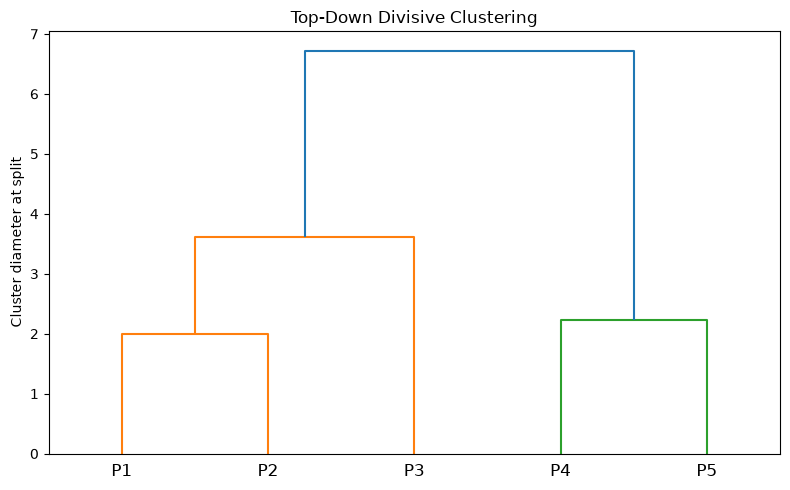